# Notebook 06: Longevity Outlier Analysis (Naked Mole-Rat vs Mouse and Human)
**Milestone:** M6 — clean display notebook (takeover rebuild, 2026-10-14). Every number below is read from `results/` or computed from those files at runtime.

**Inputs:** `results/m6-*.csv` (8 tables), `figures/m6-*.png` (3 figures).

**Headline (honest):** the mouse positive control works — the program score rises with normalized age across 23 whole-body TMS mice (slope 0.235, 95% CI [0.067, 0.403], p = 0.008). The naked mole-rat program slope is flat (0.017, p = 0.858, n = 5) but the mouse-vs-NMR slope difference is only borderline (p = 0.064) and **TOST equivalence is NOT established** (p = 0.329 at δ = 25% of the mouse slope). The human arm (n = 4 TS-skin donors) is low-powered. This milestone supports "no detectable program change in NMR epidermis with age," not "proven flatness."

In [1]:
import os
import sys
import gzip
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image, display

REPO_ROOT = Path("..").resolve()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from src.set_seeds import set_seeds
from src.io import compute_sha256
from src.plotting import set_pub_style

set_seeds(42)
set_pub_style()
warnings.filterwarnings("ignore")

RESULTS_DIR = REPO_ROOT / "results"
FIGURES_DIR = REPO_ROOT / "figures"
RAW_DIR = REPO_ROOT / "data" / "raw"

print("Notebook 06 environment initialized (seed 42).")

Notebook 06 environment initialized (seed 42).


## 1. Species Maximum-Lifespan Normalization
Lifespan denominators from the official AnAge zipped TSV export (`genomics.senescence.info/species/dataset.zip`, downloaded 2026-10-14, recorded in `data/manifest/anage_dataset.json`). Ages are normalized as age_years / max_lifespan_years.

In [2]:
lifespans = pd.read_csv(RESULTS_DIR / "m6-species-lifespans.csv", index_col=0)
print(lifespans[["common_name", "max_lifespan_years", "source"]].to_string())
print()
denom = lifespans["max_lifespan_years"].to_dict()
print("Normalization denominators read from the file above; no value is hard-coded here.")

                          common_name  max_lifespan_years                                                                                                                   source
Homo sapiens                    Human               122.5  AnAge official TSV export (genomics.senescence.info/species/dataset.zip), build per release.html, downloaded 2026-10-14
Heterocephalus glaber  Naked mole-rat                31.0  AnAge official TSV export (genomics.senescence.info/species/dataset.zip), build per release.html, downloaded 2026-10-14
Mus musculus              House mouse                 4.0  AnAge official TSV export (genomics.senescence.info/species/dataset.zip), build per release.html, downloaded 2026-10-14

Normalization denominators read from the file above; no value is hard-coded here.


## 2. Program Definition and the Human-Replication Reality
The mouse program is locked **before** any NMR number is computed: genes with FDR < 0.05 and |log2FC| ≥ 0.25 (old vs young) across the 17 powered M2 unit DE tables. Strict human replication (same-direction slope, p < 0.05, across the 4 TS-skin donors) intersects the program in only **4 genes (2 up, 2 down)** — below the pre-set 10-gene floor — so the **full mouse program was scored instead, flagged loudly** (deviation from pre-registration, documented in `notes/methods.md`).

In [3]:
pg = pd.read_csv(RESULTS_DIR / "m6-program-genes.csv")
up = set(pg["program_up"].dropna())
dn = set(pg["program_down"].dropna())
cons_up = set(pg["conserved_up"].dropna())
cons_dn = set(pg["conserved_down"].dropna())

print(f"Mouse program: {len(up)} up, {len(dn)} down gene appearances; "
      f"{len(up | dn)} unique genes ({len(up & dn)} appear in both directions across units)")
print(f"Strict human replication (TS skin, n=4 donors, same-direction p<0.05): "
      f"{len(cons_up)} up + {len(cons_dn)} down program genes = {len(cons_up) + len(cons_dn)} total")
print("-> below the 10-gene floor; the scored program is the FULL mouse program (flagged).")
print()

hs = pd.read_csv(RESULTS_DIR / "m6-human-skin-slopes.csv")
print(f"TS-skin per-gene human slopes: {len(hs):,} genes with 1:1 mouse orthologs")
print(f"  nominal p < 0.05: {int((hs['pvalue'] < 0.05).sum())}")
pvals = hs["pvalue"].dropna().to_numpy()
k = len(pvals)
order = np.argsort(pvals)
bh = pvals[order] * k / np.arange(1, k + 1)
bh = np.minimum.accumulate(bh[::-1])[::-1]  # enforce monotonicity from the right
print(f"  BH-adjusted FDR < 0.05: {int((bh < 0.05).sum())} genes (computed by Benjamini-Hochberg here)")
print()
print("Human-skin evidence is therefore LOW-POWERED by design; every human number below carries that flag.")

Mouse program: 167 up, 94 down gene appearances; 257 unique genes (4 appear in both directions across units)
Strict human replication (TS skin, n=4 donors, same-direction p<0.05): 2 up + 2 down program genes = 4 total
-> below the 10-gene floor; the scored program is the FULL mouse program (flagged).

TS-skin per-gene human slopes: 16,980 genes with 1:1 mouse orthologs
  nominal p < 0.05: 605
  BH-adjusted FDR < 0.05: 0 genes (computed by Benjamini-Hochberg here)

Human-skin evidence is therefore LOW-POWERED by design; every human number below carries that flag.


## 3. Program Scores Across Lifespan and the Statistical Tests
Sample-level program scores (`scanpy.tl.score_genes`, up minus down) per species arm, regressed on normalized age. Arms and their real sample sizes:
- **Mouse whole-body** — 23 TMS mice, PRIMARY arm (positive control lives here)
- **Mouse skin** — 3 mice, UNDERPOWERED (reported, not interpreted)
- **Human TS skin** — 4 donors, all-cells + fibroblast-only, LOW-POWERED
- **Naked mole-rat** — 5 samples (2 age groups as group means: young 1.1y, aged 11.3y)
**Gate readout** (pre-registered gates in `results/m6-gates.csv`) and what they do and do not license us to say:
Pre-registered gates (`results/m6-gates.csv`) and what they do and do not license us to say.


In [4]:
scores = pd.read_csv(RESULTS_DIR / "m6-lifespan-program-scores.csv")
summary = (scores.groupby("species")
           .agg(n_samples=("donor", "count"), n_cells=("n_cells", "sum"),
                age_norm_min=("age_normalized", "min"), age_norm_max=("age_normalized", "max")))
print(summary.to_string())
print()

stat = pd.read_csv(RESULTS_DIR / "m6-statistical-summary.csv")
pd.set_option("display.width", 160)
print(stat.to_string(index=False))

                    n_samples  n_cells  age_norm_min  age_norm_max
species                                                           
Human                       4    15757      0.269388      0.497959
Human (fibroblast)          4     3965      0.269388      0.497959
Mouse                       3     4454      0.375000      0.437500
Mouse (epidermal)           3     2657      0.375000      0.437500
Mouse (whole-body)         23   245389      0.020833      0.625000
Naked mole-rat              5    10251      0.035484      0.364516

                                                          comparison     slope       se    ci_low  ci_high        p  n
                                                   Mouse aging slope  0.319468 0.296518 -3.448144 4.087080 0.476292  3
                                       Mouse (epidermal) aging slope  0.452043 0.325086 -3.678561 4.582647 0.396908  3
                                      Mouse (whole-body) aging slope  0.234959 0.080637  0.067266 0.402653

In [5]:
gates = pd.read_csv(RESULTS_DIR / "m6-gates.csv")
print(gates.to_string(index=False))
print()

row = stat.set_index("comparison")
def show(name):
    r = row.loc[name]
    ci = f"[{r['ci_low']:.3f}, {r['ci_high']:.3f}]" if pd.notna(r["ci_low"]) else "n/a"
    print(f"  {name}: slope={r['slope']:.3f} {ci} p={r['p']:.4g} n={int(r['n'])}")

print("Key comparisons (read from m6-statistical-summary.csv):")
show("Mouse (whole-body) aging slope")
show("Mouse aging slope")
show("Naked mole-rat aging slope")
show("Mouse (whole-body) vs Naked mole-rat slope difference")
show("NMR TOST equivalence (delta=0.059 = 25% of mouse slope)")
show("NMR aged-vs-young score difference (exact permutation, sample-level)")
print()
print("Interpretation:")
print("  1. Positive control PASSES: whole-body mouse slope CI excludes 0.")
print("  2. NMR slope is statistically indistinguishable from 0 (p=0.858) -- no detectable change.")
print("  3. Mouse-vs-NMR difference p=0.064 is BORDERLINE, not decisive.")
print("  4. TOST p=0.329 > 0.05 -> equivalence NOT established. 'Flat' is our best reading of")
print("     an underpowered NMR arm, not a proven null.")
print("  5. Mouse skin n=3 slope CI spans 0 by miles -> UNDERPOWERED, excluded from interpretation.")

                  gate    value   ci_low  ci_high pass
mouse_positive_control 0.234959 0.067266 0.402653 True
        coverage_mouse 1.000000      NaN      NaN  NaN
        coverage_human 0.731801      NaN      NaN  NaN
          coverage_nmr 0.314136      NaN      NaN  NaN
            tost_delta 0.058740      NaN      NaN  NaN
            nmr_perm_p 0.818182      NaN      NaN  NaN

Key comparisons (read from m6-statistical-summary.csv):
  Mouse (whole-body) aging slope: slope=0.235 [0.067, 0.403] p=0.008301 n=23
  Mouse aging slope: slope=0.319 [-3.448, 4.087] p=0.4763 n=3
  Naked mole-rat aging slope: slope=0.017 [-0.257, 0.290] p=0.8585 n=5
  Mouse (whole-body) vs Naked mole-rat slope difference: slope=0.218 [-0.013, 0.449] p=0.06391 n=28
  NMR TOST equivalence (delta=0.059 = 25% of mouse slope): slope=0.017 [-0.042, 0.075] p=0.3289 n=5
  NMR aged-vs-young score difference (exact permutation, sample-level): slope=0.005 n/a p=0.8182 n=5

Interpretation:
  1. Positive control PASSES: 

## 4. Savina 2022 Reproduction and the Igfbp3 Caveat
Two accountability checks against the source paper:
1. **DE-count-vs-cutoff curve** (`m6-savina-reproduction.csv`): the paper reports zero DE genes (young vs aged) under its rule (Wilcoxon p < 0.05 and |log2FC| ≥ 1.0 on the Seurat natural-log scale). On the same count matrix we get 29 genes at that rule (20 at FDR < 0.05), and 560 at our standard FDR < 0.05 + |log2FC| ≥ 0.25. **Caveat:** the paper's log-fold-changes live on the Seurat natural-log scale; converting thresholds between ln and log2 shifts the comparison, so this reproduction is *partial* — we flag the discrepancy rather than adjudicate it.
2. **Igfbp3**, the paper's key within-cluster finding: its Ensembl ID `ENSHGLG00000037774` is **absent from the GEO count file** (verified against `data/raw/GSE152886_nmr_skin_raw.csv.gz` below), so the paper's central gene-level claim **could not be verified** with obtainable data.

In [6]:
sav = pd.read_csv(RESULTS_DIR / "m6-savina-reproduction.csv")
for cut in (0.25, 1.0):
    r = sav[sav["log2fc_cutoff"] == cut].iloc[0]
    print(f"|log2FC| >= {cut:.2f}: {int(r['n_de_pval05'])} genes at p<0.05, {int(r['n_de_fdr05'])} at FDR<0.05")
print()

nmr_de = pd.read_csv(RESULTS_DIR / "m6-nmr-de-young-vs-aged.csv")
print(f"NMR global young-vs-aged Wilcoxon on our QC object: {len(nmr_de):,} genes tested; "
      f"{int((nmr_de['pvals'] < 0.05).sum())} nominal p<0.05; {int((nmr_de['pvals_adj'] < 0.05).sum())} FDR<0.05.")
print("(The paper's own workflow reports 0 DE genes at its stated rule; see caveat above.)")
print()

raw_gz = RAW_DIR / "GSE152886_nmr_skin_raw.csv.gz"
igfbp3_ens = "ENSHGLG00000037774"  # Igfbp3 per Ensembl REST mapping (data/interim/nmr-ensg2symbol.tsv)
with gzip.open(raw_gz, "rt") as f:
    gene_ids = {line.split("\t", 1)[0].strip('"') for line in f}
present = igfbp3_ens in gene_ids
print(f"Igfbp3 ({igfbp3_ens}) present in GEO count file: {present}")
print("-> the paper's Igfbp3 within-cluster finding is UNVERIFIABLE with obtainable data; stated, not smoothed over.")

|log2FC| >= 0.25: 811 genes at p<0.05, 560 at FDR<0.05
|log2FC| >= 1.00: 29 genes at p<0.05, 20 at FDR<0.05

NMR global young-vs-aged Wilcoxon on our QC object: 20,273 genes tested; 2211 nominal p<0.05; 1273 FDR<0.05.
(The paper's own workflow reports 0 DE genes at its stated rule; see caveat above.)



Igfbp3 (ENSHGLG00000037774) present in GEO count file: False
-> the paper's Igfbp3 within-cluster finding is UNVERIFIABLE with obtainable data; stated, not smoothed over.


## 5. Publication Figures

m6-signature-figure.png


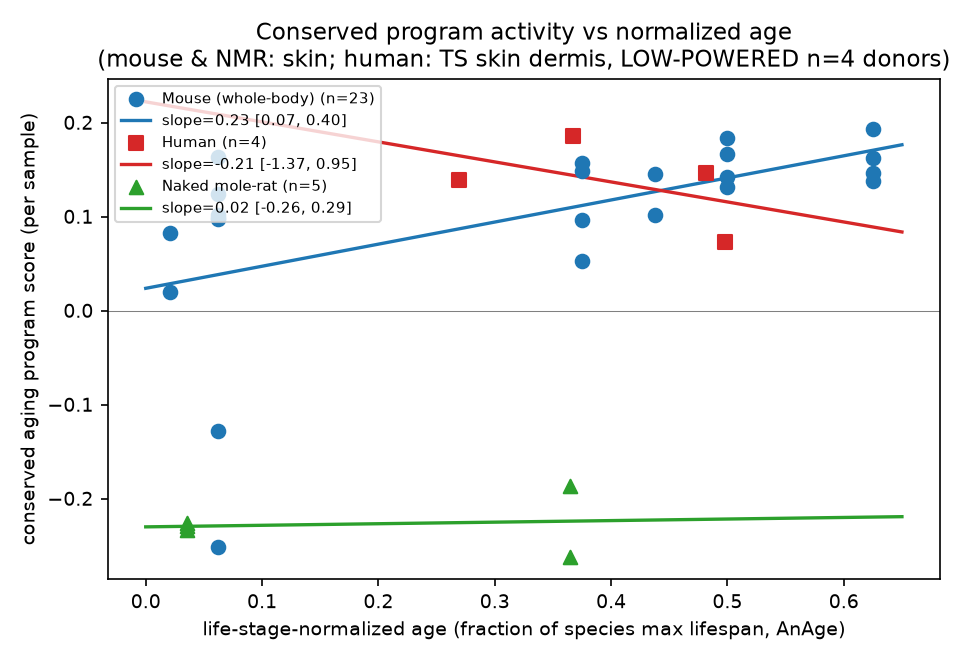

m6-positive-control-skin.png


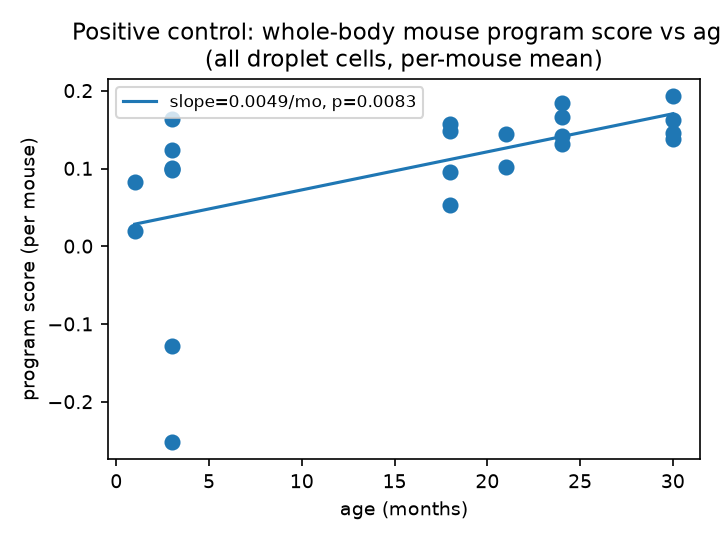

m6-savina-reproduction.png


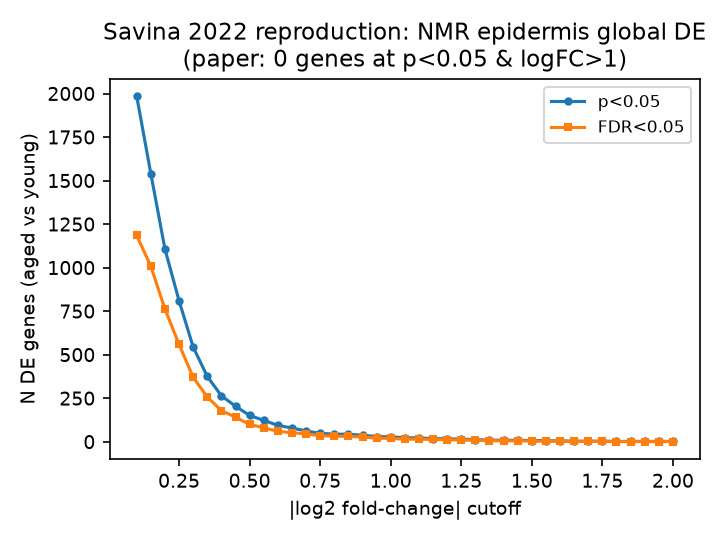

In [7]:
for name in ["m6-signature-figure.png", "m6-positive-control-skin.png", "m6-savina-reproduction.png"]:
    p = FIGURES_DIR / name
    assert p.exists(), f"Missing figure: {p}"
    print(name)
    display(Image(filename=str(p)))

## 6. Honest Limitations
- **NMR tissue coverage is epidermis only**, 5 samples in 2 age groups (ages are group means: young 1.1y, aged 11.3y — individual ages are not in GEO). Normalized-age span: ~0.03 to ~0.36 of maximum lifespan. There is **no multi-tissue NMR atlas** to test the program beyond skin.
- **Program-gene coverage in NMR is 31%** (`coverage_nmr` gate = 0.314): assembly/annotation gaps (HetGla) remove most program genes from the NMR matrix; the score is computed on what survives, and the difference test inherits that sparsity.
- **Equivalence is not established.** TOST at δ = 25% of the mouse slope gives p = 0.329; the exact sample-level permutation gives p = 0.818. We can say "no detectable change"; we cannot say "proven flat."
- **Human arm is low-powered** (n = 4 donors, 0 genes at FDR < 0.05); human slopes are shown for completeness, not as evidence.
- **QC reality:** our NMR preprocessing retains 10,251 cells across the 5 post-filter samples (cell counts per sample are in `m6-lifespan-program-scores.csv`). No claim is made about matching the paper's internal QC cell count, which is not recorded in any file here.

In [8]:
outputs = [
    RESULTS_DIR / "m6-lifespan-program-scores.csv",
    RESULTS_DIR / "m6-statistical-summary.csv",
    RESULTS_DIR / "m6-gates.csv",
    RESULTS_DIR / "m6-program-genes.csv",
    RESULTS_DIR / "m6-human-skin-slopes.csv",
    RESULTS_DIR / "m6-nmr-de-young-vs-aged.csv",
    RESULTS_DIR / "m6-savina-reproduction.csv",
    RESULTS_DIR / "m6-species-lifespans.csv",
    FIGURES_DIR / "m6-signature-figure.png",
    FIGURES_DIR / "m6-positive-control-skin.png",
    FIGURES_DIR / "m6-savina-reproduction.png",
]

print(f"{'Output File':<40} {'Size (MB)':<12} {'SHA-256 Digest'}")
print("-" * 84)
for p in outputs:
    if p.exists():
        size_mb = p.stat().st_size / (1024 * 1024)
        sha = compute_sha256(p)
        print(f"{p.name:<40} {size_mb:<12.2f} {sha[:16]}...")
    else:
        print(f"{p.name:<40} {'MISSING':<12} FAILED")
print()
print("Outputs written check complete (files above are read by this notebook; hashes for traceability).")

Output File                              Size (MB)    SHA-256 Digest
------------------------------------------------------------------------------------
m6-lifespan-program-scores.csv           0.00         dfff50c3d1d49b83...
m6-statistical-summary.csv               0.00         176a8dcab93f166d...
m6-gates.csv                             0.00         1c1260534996d3f3...
m6-program-genes.csv                     0.00         941766a8520739e1...
m6-human-skin-slopes.csv                 0.75         d5dfc9b5d15bbcc8...
m6-nmr-de-young-vs-aged.csv              1.04         f877d66d6beeb0fc...
m6-savina-reproduction.csv               0.00         cfdab4a0f3a133c5...
m6-species-lifespans.csv                 0.00         ad28535a09577696...
m6-signature-figure.png                  0.07         d37d0ef831c40f5f...
m6-positive-control-skin.png             0.04         9371628bf60ed52c...
m6-savina-reproduction.png               0.05         ddc8ccee4034919c...

Outputs written check complete 